# Training targets for the upper tanks (3 and 4) — option A

Everything in `merged.csv` is in **%** (levels and flows), so the physical parameters of `main.pdf`
(A in m², k in m³/s) can't be plugged in directly. Instead the model is written in % units and the
one unknown scale factor is **estimated from the data**.

Upper tank (tank 3 fed by pump 2, tank 4 by pump 1):

$$\frac{dh}{dt} = b\,\big(q - g(h)\big)$$

- $h$ : level [%] $\quad q$ : flow of the pump that feeds this tank [% of FIT]
- $b$ : lumped constant $(1-\gamma)\,k / (A\,H)$ in [%/s per %] — estimated here
- $g(h)$ : **the pump flow [% of FIT] that exactly balances the outflow at level $h$**. At equilibrium
  $q = g(h)$, so $g(h_{ref})$ is directly the flow setpoint that holds the tank at $h_{ref}$ — the
  steady-state feedforward. $g$ is the outflow law expressed in pump-flow units; it is what ANFIS learns.

Target for every sample: $\;g = q - \dfrac{1}{b}\dfrac{dh}{dt}$

Output: `train_tankN.csv` and `check_tankN.csv` with two columns, `h, g`, for MATLAB `anfis`.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

MERGED = Path("processed/merged.csv")
OUT_DIR = Path("processed")

TS = 0.1                 # raw sample time [s]
SG_WINDOW = 101          # Savitzky-Golay window [samples] (10 s): smoothing + derivative
SG_ORDER = 2
DOWN = 10                # keep 1 sample in 10 -> 1 s
BIN_W = 2.0              # width [%] of the level bins used to estimate b

# upper tank -> the pump flow that feeds it, and gamma of that pump's 3-way valve (main.pdf, Table 1.1)
UPPER = {3: {"q": "FIT_02", "vf": "VF02", "one_minus_gamma": 1 - 0.415},
         4: {"q": "FIT_01", "vf": "VF01", "one_minus_gamma": 1 - 0.455}}

plt.rcParams["figure.figsize"] = (12, 4)

## 1. Load

`merged.csv` comes from `consistencia_datos.ipynb`. The zero-flow fix is applied again here; it does
nothing if it was already applied there.

In [4]:
m = pd.read_csv(MERGED)
for t, cfg in UPPER.items():
    off = m[cfg["vf"]] <= 0.5
    m.loc[off, cfg["q"]] = 0.0
print(m.shape)
print([c for c in m.columns])

(57770, 11)
['VF01', 'VF02', 'FIT_01', 'FIT_02', 'LIT_01', 'LIT_02', 'LIT_03', 'flag_LIT_03', 'LIT_04', 't_s', 'hora_s']


## 2. Smoothing and derivative (on the full, continuous 100 ms grid)

A Savitzky–Golay filter fits a 2nd-order polynomial in a sliding 10 s window. Its value gives the
smoothed level, its slope gives $dh/dt$ — with no phase lag, and without differentiating raw noise.
The flow is smoothed with the same window so both sides of the balance see the same time resolution.

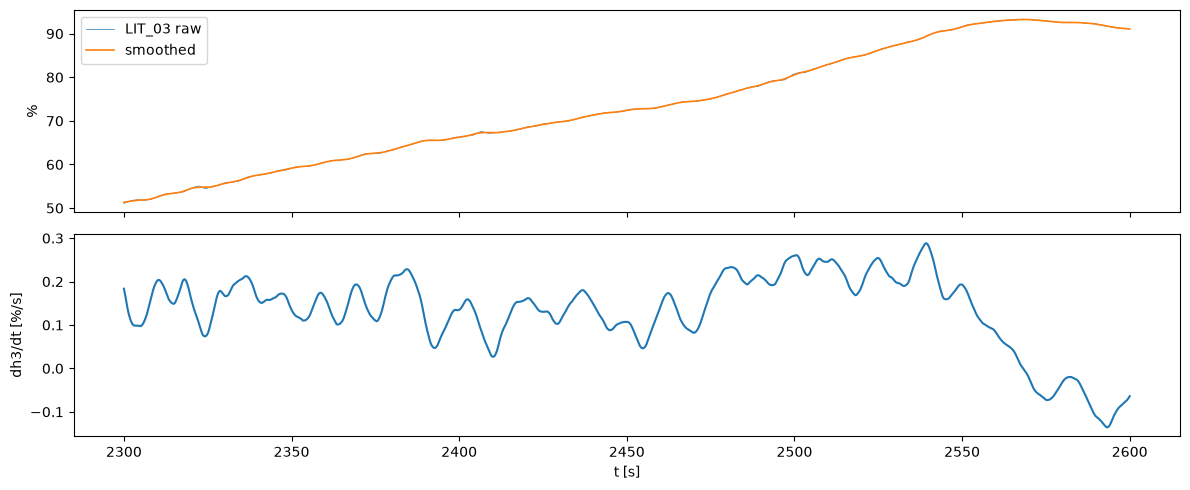

In [5]:
for t, cfg in UPPER.items():
    h = m[f"LIT_0{t}"].to_numpy()
    m[f"h{t}"] = savgol_filter(h, SG_WINDOW, SG_ORDER)
    m[f"dh{t}"] = savgol_filter(h, SG_WINDOW, SG_ORDER, deriv=1, delta=TS)       # [%/s]
    m[f"q{t}"] = savgol_filter(m[cfg["q"]].to_numpy(), SG_WINDOW, SG_ORDER)

# visual check on a 5-minute stretch
w = m["t_s"].between(2300, 2600)
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(12, 5))
ax[0].plot(m.loc[w, "t_s"], m.loc[w, "LIT_03"], lw=0.5, label="LIT_03 raw")
ax[0].plot(m.loc[w, "t_s"], m.loc[w, "h3"], lw=1.2, label="smoothed"); ax[0].legend(); ax[0].set_ylabel("%")
ax[1].plot(m.loc[w, "t_s"], m.loc[w, "dh3"]); ax[1].set_ylabel("dh3/dt [%/s]"); ax[1].set_xlabel("t [s]")
plt.tight_layout(); plt.show()

## 3. Valid samples

Invalid: repaired samples (`flag_*`) widened by one filter window on each side (the filter spreads any
repair over its whole window), and the first/last half-window where the filter has no full support.

In [6]:
half = SG_WINDOW // 2
edge = pd.Series(False, index=m.index)
edge.iloc[:half] = True
edge.iloc[-half:] = True

for t in UPPER:
    flag = m.get(f"flag_LIT_0{t}", pd.Series(False, index=m.index)).astype(bool)
    near_flag = flag.rolling(2 * SG_WINDOW + 1, center=True, min_periods=1).max().astype(bool)
    m[f"valid{t}"] = ~(near_flag | edge)
    print(f"tank {t}: {(~m[f'valid{t}']).sum()} invalid samples")

tank 3: 342 invalid samples
tank 4: 100 invalid samples


## 4. Downsample to 1 s

The tank time constants are minutes; consecutive 100 ms samples carry almost the same information.

In [7]:
d = m.iloc[::DOWN].reset_index(drop=True)
print(d.shape)

(5777, 19)


## 5. Estimate $b$ for each tank

$dh/dt = b\,q - f(h)$ with $f$ unknown. Represent $f$ as one constant per 2 % level bin; then the
equation is **linear** in $b$ and the bin constants, and least squares solves all of them at once.
$b$ is identifiable because the same level is visited with different pump flows (and with the pump off).

**Check:** with the same pump gain on both pumps, $b_3/b_4$ should equal $(1-\gamma_2)/(1-\gamma_1)$.

In [8]:
def estimate_b(h, dh, q, bin_w=BIN_W):
    bins = np.arange(0, 100 + bin_w, bin_w)
    idx = np.digitize(h, bins)
    ub = np.unique(idx)
    X = np.zeros((len(h), 1 + len(ub)))
    X[:, 0] = q
    for j, u in enumerate(ub):
        X[idx == u, 1 + j] = -1.0
    sol, *_ = np.linalg.lstsq(X, dh, rcond=None)
    b = sol[0]
    centers = bins[ub - 1] + bin_w / 2
    g_bins = sol[1:] / b                       # g(h) per bin, in pump-flow %
    resid = dh - X @ sol
    return b, centers, g_bins, resid

B, GBIN = {}, {}
for t in UPPER:
    s = d[d[f"valid{t}"]]
    b, centers, g_bins, resid = estimate_b(s[f"h{t}"].to_numpy(), s[f"dh{t}"].to_numpy(), s[f"q{t}"].to_numpy())
    B[t], GBIN[t] = b, (centers, g_bins)
    print(f"tank {t}: b = {b:.5f} %/s per %   (residual std {resid.std():.4f} %/s)")

ratio_data = B[3] / B[4]
ratio_theory = UPPER[3]["one_minus_gamma"] / UPPER[4]["one_minus_gamma"]
print(f"\nb3/b4 from data = {ratio_data:.3f}   (1-γ2)/(1-γ1) from main.pdf = {ratio_theory:.3f}")

tank 3: b = 0.01111 %/s per %   (residual std 0.0580 %/s)
tank 4: b = 0.01047 %/s per %   (residual std 0.0345 %/s)

b3/b4 from data = 1.061   (1-γ2)/(1-γ1) from main.pdf = 1.073


## 6. Targets and the identified curve

Each sample gives $g = q - \frac{1}{b}\frac{dh}{dt}$. The scatter should follow one clean curve; the
bin estimates from step 5 are overlaid, plus the best **pure Torricelli** shape $g=\alpha\sqrt{h}$ for comparison.

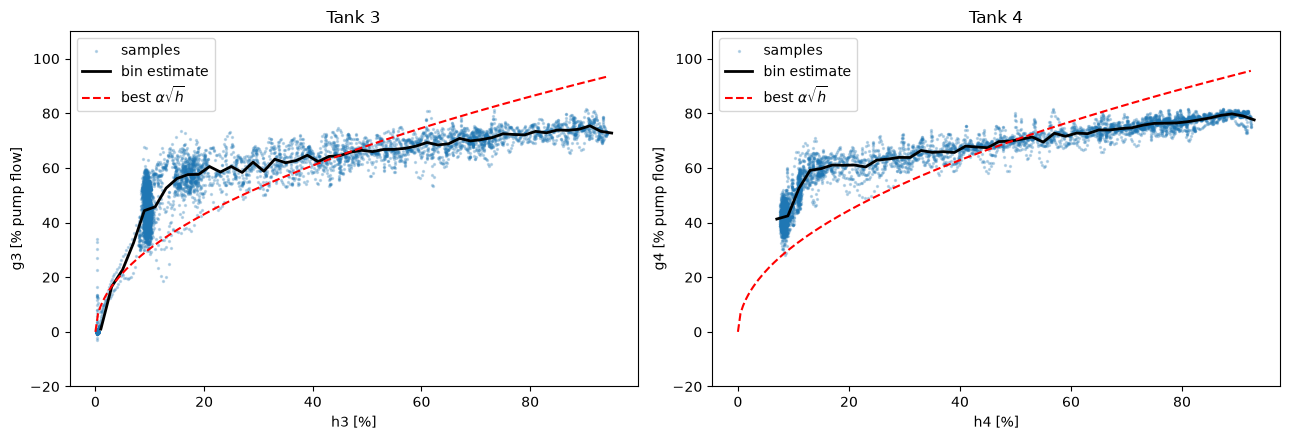

In [9]:
fig, axes = plt.subplots(1, len(UPPER), figsize=(13, 4.5), squeeze=False)
for ax, t in zip(axes[0], UPPER):
    d[f"g{t}"] = d[f"q{t}"] - d[f"dh{t}"] / B[t]
    s = d[d[f"valid{t}"]]
    ax.scatter(s[f"h{t}"], s[f"g{t}"], s=2, alpha=0.25, label="samples")
    c, gb = GBIN[t]
    ax.plot(c, gb, "k-", lw=2, label="bin estimate")
    hh = np.linspace(0, s[f"h{t}"].max(), 200)
    alpha = np.sum(s[f"g{t}"] * np.sqrt(s[f"h{t}"].clip(0))) / np.sum(s[f"h{t}"].clip(0))
    ax.plot(hh, alpha * np.sqrt(hh), "r--", label=r"best $\alpha\sqrt{h}$")
    ax.set_xlabel(f"h{t} [%]"); ax.set_ylabel(f"g{t} [% pump flow]"); ax.set_title(f"Tank {t}")
    ax.legend(); ax.set_ylim(-20, 110)
plt.tight_layout(); plt.show()

## 7. Structure check: free-run simulation

Before any ANFIS: simulate $h(k+1) = h(k) + T\,b\,(q(k) - g(h(k)))$ with the **recorded** pump flow and
the bin curve from step 5, starting from the first measured level, never correcting with measurements.
If this follows the measured level over the whole recording, the model structure and $b$ are right,
and ANFIS only has to learn a smooth version of $g$.

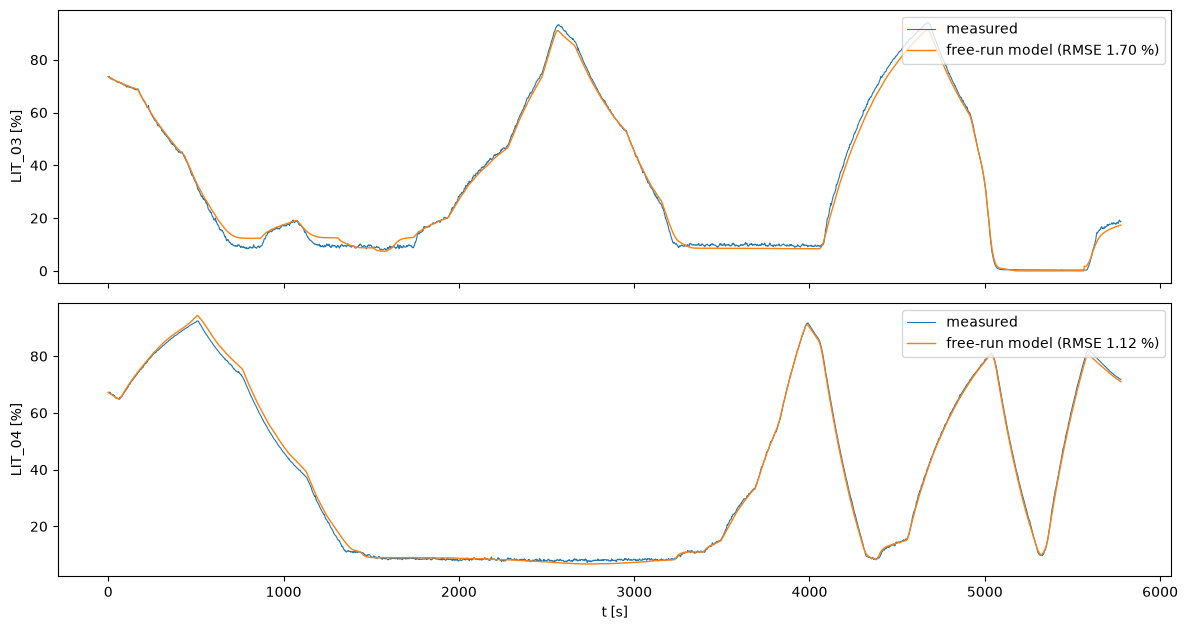

In [10]:
T = TS * DOWN
fig, axes = plt.subplots(len(UPPER), 1, figsize=(12, 3.2 * len(UPPER)), sharex=True, squeeze=False)
for ax, (t, cfg) in zip(axes[:, 0], UPPER.items()):
    q = d[cfg["q"]].to_numpy()
    meas = d[f"LIT_0{t}"].to_numpy()
    c, gb = GBIN[t]
    x, sim = meas[0], []
    for k in range(len(q)):
        sim.append(x)
        x = max(x + T * B[t] * (q[k] - np.interp(x, c, gb)), 0.0)
    sim = np.array(sim)
    rmse = np.sqrt(np.mean((sim - meas) ** 2))
    ax.plot(d["t_s"], meas, lw=0.8, label="measured")
    ax.plot(d["t_s"], sim, lw=1.0, label=f"free-run model (RMSE {rmse:.2f} %)")
    ax.set_ylabel(f"LIT_0{t} [%]"); ax.legend(loc="upper right")
axes[-1, 0].set_xlabel("t [s]")
plt.tight_layout(); plt.show()

## 8. Split into training and checking sets (by time)

Choose `SPLIT_T` so that **every level band appears in both sets** — check the table before exporting.

In [11]:
SPLIT_T = 4000          # [s]  training: t < SPLIT_T, checking: t >= SPLIT_T
BANDS = [0, 20, 40, 60, 80, 100]

sets = {}
for t in UPPER:
    s = d.loc[d[f"valid{t}"], ["t_s", f"h{t}", f"g{t}"]].rename(columns={f"h{t}": "h", f"g{t}": "g"})
    trn, chk = s[s["t_s"] < SPLIT_T], s[s["t_s"] >= SPLIT_T]
    sets[t] = (trn, chk)
    cov = pd.DataFrame({
        "train": pd.cut(trn["h"], BANDS, include_lowest=True).value_counts(sort=False),
        "check": pd.cut(chk["h"], BANDS, include_lowest=True).value_counts(sort=False)})
    print(f"--- tank {t}  (samples at 1 s)"); print(cov)

--- tank 3  (samples at 1 s)
                train  check
h                           
(-0.001, 20.0]   2143    854
(20.0, 40.0]      515    130
(40.0, 60.0]      589    182
(60.0, 80.0]      540    297
(80.0, 100.0]     208    284
--- tank 4  (samples at 1 s)
                train  check
h                           
(-0.001, 20.0]   2263    408
(20.0, 40.0]      374    310
(40.0, 60.0]      342    333
(60.0, 80.0]      536    563
(80.0, 100.0]     480    158


## 9. Balance the training set

Cap the samples per band so the low-level region doesn't dominate the least-squares fit.
The checking set is **not** balanced: it should reflect real operation.

In [12]:
CAP_FACTOR = 3          # cap = CAP_FACTOR x the smallest non-empty band

def balance(df, bands, cap_factor, seed=0):
    band = pd.cut(df["h"], bands, include_lowest=True)
    counts = band.value_counts()
    cap = int(cap_factor * counts[counts > 0].min())
    out = (df.groupby(band, observed=True, group_keys=False)
             .apply(lambda grp: grp.sample(min(len(grp), cap), random_state=seed)))
    return out.sort_values("t_s"), cap

for t in UPPER:
    trn, chk = sets[t]
    trn_b, cap = balance(trn, BANDS, CAP_FACTOR)
    sets[t] = (trn_b, chk)
    print(f"tank {t}: cap {cap} per band -> train {len(trn)} -> {len(trn_b)} samples")

tank 3: cap 624 per band -> train 3995 -> 2476 samples
tank 4: cap 1026 per band -> train 3995 -> 2758 samples


## 10. Export for MATLAB

Two columns only, `h, g` (input, target). `readmatrix` skips the header line.
`b` is saved too: the plant model and the feedforward need it.

In [13]:
OUT_DIR.mkdir(exist_ok=True)
for t in UPPER:
    trn, chk = sets[t]
    trn[["h", "g"]].to_csv(OUT_DIR / f"train_tank{t}.csv", index=False)
    chk[["h", "g"]].to_csv(OUT_DIR / f"check_tank{t}.csv", index=False)
    print(f"tank {t}: train {len(trn)}, check {len(chk)}")

pd.Series({f"b{t}": B[t] for t in UPPER}).to_csv(OUT_DIR / "b_upper.csv", header=["value"])
print(pd.read_csv(OUT_DIR / "b_upper.csv", index_col=0))

tank 3: train 2476, check 1747
tank 4: train 2758, check 1772
       value
b3  0.011106
b4  0.010468
